In [1]:
import numpy as np
import os
import time
import scipy
import pandas as pd
import tensorflow as tf
from tensorflow import keras
import matplotlib.pyplot as plt
from matplotlib import cm

#Want to use version of Tensorflow > 2.0
print('Using Tensorflow version %s' % tf.__version__)
font = {'family': 'serif', \
        'color':  'darkred' \
        }

Using Tensorflow version 2.10.1


In [2]:
def writeFile(new_df, fileName):
    new_df.to_csv(fileName, sep=' ', index=False)#, header=None)

In [3]:
#columns for input with all FFA parameters and output with only fixfield format particle data

fixfield_headers =  ["m0 [MeV*c^-2]", "q [unit charge]", "x [m]", "y [m]", "z [m]", "Ptot [MeV/c]", "ux []", "uy []", "uz []"]

fixfield_phase_space_headers =  ["x [m]", "y [m]", "z [m]", "ux []", "uy []", "uz []"]

fixfield_para_headers =  ["rmin [m]", "rmax [m]", "zmax [m]", "Cell opening angle [deg]", "r0 [m]", "k_val",
                        "C1", "lambda0",  "mag0 B0 [T]",  "mag0 cent_theta[deg]", "mag0 length_theta[deg]", 
                        "mag1 B0 [T]",  "mag1 cent_theta[deg]", "mag1 length_theta[deg]", "mag2 B0 [T]",  "mag2 cent_theta[deg]", "mag2 length_theta[deg]"]

ML_sample_headers =  ["rmin [m]", "rmax [m]", "zmax [m]", "Cell opening angle [deg]", "r0 [m]", "k_val",
                        "C1", "lambda0",  "mag0 B0 [T]",  "mag0 cent_theta[deg]", "mag0 length_theta[deg]", 
                        "mag1 B0 [T]",  "mag1 cent_theta[deg]", "mag1 length_theta[deg]", "mag2 B0 [T]",  "mag2 cent_theta[deg]", "mag2 length_theta[deg]", 
                        "m0 [MeV*c^-2]", "q [unit charge]", "x [m]", "y [m]", "z [m]", "Ptot [MeV/c]", "ux []", "uy []", "uz []"]

LhARA_columns = ['x', 'xp', 'y', 'yp', 'z', 'E']

print("input col num : "+str(len(ML_sample_headers))+", output col num : "+str(len(fixfield_headers)))
print(len(fixfield_para_headers))

input col num : 26, output col num : 9
17


In [4]:
#fixfield_headers =  ["m0 [MeV*c^-2]", "q [unit charge]", "x [m]", "y [m]", "z [m]", "Ptot [MeV/c]", "ux []", "uy []", "uz []"]
#LhARA_columns = ['x', 'xp', 'y', 'yp', 'z', 'E'] -> x,y in cm

def fixfield_to_LhARA(fixfield_np_lst): #convert fixfield_headers to LhARA_columns
    
    FFA_total_type_num = len(fixfield_np_lst)
    total_part_per_FFA = len(fixfield_np_lst[0])
    coulumn_num = len(LhARA_columns)

    LhARA_np_lst = np.zeros((FFA_total_type_num,total_part_per_FFA,coulumn_num), dtype="float32")

    for FFA_num in range(0, FFA_total_type_num):
        for part_num in range(0, total_part_per_FFA):
            fixfield_part = fixfield_np_lst[FFA_num][part_num]

            #x,y,z
            LhARA_np_lst[FFA_num][part_num][0] = fixfield_part[2]#*1e2
            LhARA_np_lst[FFA_num][part_num][2] = fixfield_part[4]#*1e2
            LhARA_np_lst[FFA_num][part_num][4] = fixfield_part[3]#*1e2 #in fixfield y is the beam axis while in LhARA z is

            #xp, yp
            LhARA_np_lst[FFA_num][part_num][1] = fixfield_part[6]
            LhARA_np_lst[FFA_num][part_num][3] = fixfield_part[8]

            #E MeV -> GeV
            LhARA_np_lst[FFA_num][part_num][5] = np.sqrt((fixfield_part[5]/1e3)**2+(fixfield_part[0]/1e3)**2)

    
    return LhARA_np_lst

In [81]:
def reconstruct_output(input_particles,
                       output_particles,
                       momentum_tol=1e-3,
                       mass_tol=1e-6):

    """
    input_particles:
        (N, 9) original FixField particles

    output_particles:
        (N, 9) reconstructed output, including zero rows

    Returns:
        reconstructed: (N, 9), correct original ordering
        survive_mask: (N,), True = surviving, False = lost
    """

    N = len(input_particles)

    reconstructed = np.zeros_like(input_particles)
    survive_mask = np.zeros(N, dtype=bool)

    # Column indices
    MASS = 0
    MOMENTUM = 5
    DIRECTION = [6, 7, 8]

    # Identify surviving output particles.
    # Lost particles have zero momentum direction.
    output_survive = np.any(
        np.abs(output_particles[:, DIRECTION]) > 1e-12,
        axis=1
    )

    surviving_output = output_particles[output_survive]

    # Original particle properties
    input_mass = input_particles[:, MASS]
    input_momentum = input_particles[:, MOMENTUM]

    output_mass = surviving_output[:, MASS]
    output_momentum = surviving_output[:, MOMENTUM]

    # Match each surviving output particle
    for j in range(len(surviving_output)):

        mass = output_mass[j]
        momentum = output_momentum[j]

        # Find candidates with matching mass
        mass_candidates = np.where(
            np.isclose(
                input_mass,
                mass,
                rtol=0,
                atol=mass_tol
            )
        )[0]

        if len(mass_candidates) == 0:
            raise ValueError(
                f"No matching mass found for output particle {j}"
            )

        # Find closest momentum among matching masses
        differences = np.abs(
            input_momentum[mass_candidates] - momentum
        )

        best_position = np.argmin(differences)
        original_idx = mass_candidates[best_position]

        if differences[best_position] > momentum_tol:
            raise ValueError(
                f"No momentum match for output particle {j}. "
                f"Mass={mass}, momentum={momentum}, "
                f"closest difference={differences[best_position]}"
            )

        if survive_mask[original_idx]:
            raise ValueError(
                f"Duplicate match for original particle {original_idx}"
            )

        # Restore particle at its original index
        reconstructed[original_idx] = surviving_output[j]
        survive_mask[original_idx] = True

    # Restore original mass, charge and momentum for lost particles
    lost_mask = ~survive_mask

    reconstructed[lost_mask, 0] = input_particles[lost_mask, 0]
    reconstructed[lost_mask, 1] = input_particles[lost_mask, 1]
    reconstructed[lost_mask, 5] = input_particles[lost_mask, 5]

    return reconstructed, survive_mask

In [5]:
#read generated sample data with pandas read_csv

FFA_ML_input = "ML_FFA_sample/ML_input_merged.dat"
FFA_ML_output = "ML_FFA_sample/ML_output_merged.dat"

input_df = pd.DataFrame()
input_df = pd.read_csv(FFA_ML_input, sep = "\s+", skiprows=1, names=ML_sample_headers) #input for ML contains all info of FFA magnets
input_para_df = input_df[fixfield_para_headers]
input_phase_space_df = input_df[fixfield_phase_space_headers]
input_np_lst = input_df.to_numpy()
input_para_np_lst = input_para_df.to_numpy()
input_phase_space_np_lst = input_phase_space_df.to_numpy()

output_df = pd.DataFrame()
output_df = pd.read_csv(FFA_ML_output, sep = "\s+", skiprows=1, names=fixfield_headers) #output for ML contains only particle data in form of fixfield
output_df = output_df[fixfield_phase_space_headers]
output_np_lst = output_df.to_numpy()
output_lost_lst = np.ones(len(output_df["x [m]"])) #list to tell if particle is lost or still existing  surviving  :  1   lost  :  0

print("number of particles : "+str(len(output_df["x [m]"])))

#============================================================================================================
#put the read data into np array

FFA_type_num = 15 #number of different FFA settings

total_part_num = len(output_df["x [m]"])
part_per_FFA = int(total_part_num/FFA_type_num)
sample_part_num_per_FFA = int(part_per_FFA/2)#assgin half of sample for train and other half for validation
input_col_num = len(ML_sample_headers)
input_para_col_num = len(fixfield_para_headers)
input_phase_space_col_num = len(fixfield_phase_space_headers)

FFA_parameter_len = len(fixfield_para_headers)
output_col_num = len(fixfield_phase_space_headers)

input_para_train = np.zeros((FFA_type_num,input_para_col_num), dtype="float32") #training data
input_phase_space_train = np.zeros((FFA_type_num,sample_part_num_per_FFA,input_phase_space_col_num), dtype="float32") #training data
output_train = np.zeros((FFA_type_num,sample_part_num_per_FFA,output_col_num), dtype="float32")
output_lost_train = np.ones((FFA_type_num,sample_part_num_per_FFA), dtype="float32")#list to tell if particle is lost or still existing  surviving  :  1   lost  :  0


input_para_val = np.zeros((FFA_type_num,input_para_col_num), dtype="float32") #training data
input_phase_space_val = np.zeros((FFA_type_num,sample_part_num_per_FFA,input_phase_space_col_num), dtype="float32") #training data
output_val = np.zeros((FFA_type_num,sample_part_num_per_FFA,output_col_num), dtype="float32")
output_lost_val = np.ones((FFA_type_num,sample_part_num_per_FFA), dtype="float32")#list to tell if particle is lost or still existing  surviving  :  1   lost  :  0

FFA_parameter_norm = 200
Ptot_norm = 1e4
space_norm = 2
'''
#create array for normalizing number in data to -1 ~ 1
input_norm_array = np.ones(input_col_num)
output_norm_array = np.ones(output_col_num)

for i in range(0, FFA_parameter_len):
    input_norm_array[i] = FFA_parameter_norm

for i in range(0, 3):
    input_norm_array[i+2+FFA_parameter_len] = space_norm
    output_norm_array[i] = space_norm

input_norm_array[5+FFA_parameter_len] = Ptot_norm
output_norm_array[3] = 0.04
output_norm_array[5] = 0.04
#output_norm_array[5] = Ptot_norm
'''
lost_count_train = 0
lost_count_val = 0
for FFA_num in range(0, FFA_type_num):
    input_para_train[FFA_num] = input_para_np_lst[2*FFA_num*sample_part_num_per_FFA]
    input_para_val[FFA_num] = input_para_np_lst[2*FFA_num*sample_part_num_per_FFA+1]
    
    for i in range(0,sample_part_num_per_FFA):
        part_num = FFA_num*sample_part_num_per_FFA+i
    
        input_phase_space_train[FFA_num][i] = input_phase_space_np_lst[2*part_num]
        input_phase_space_val[FFA_num][i] = input_phase_space_np_lst[2*part_num+1]
    
        output_train[FFA_num][i] = output_np_lst[2*part_num]
        output_val[FFA_num][i] = output_np_lst[2*part_num+1]
    

        #lost particles have 0 phase space val. So sum of ux,uy,uz is 0 -> lost
        if (output_train[FFA_num][i][3]+output_train[FFA_num][i][4]+output_train[FFA_num][i][5])<1e-6:
            output_lost_train[FFA_num][i] = 0#if particle is lost assign 0
            lost_count_train = lost_count_train + 1
    
        if (output_val[FFA_num][i][3]+output_val[FFA_num][i][4]+output_val[FFA_num][i][5])<1e-6:
            output_lost_val[FFA_num][i] = 0
            lost_count_val = lost_count_val + 1


print("output_train")
print(output_train)
print("input_para_train")
print(input_para_train)
print("lost_count_train : "+str(lost_count_train)+", lost_count_val : "+str(lost_count_val))
print(output_np_lst[4])
print("train particle num : "+str(len(input_phase_space_train))+", val particle num : "+str(len(input_phase_space_val))
      +", input column : "+str(len(input_phase_space_train[0]))+",  output column : "+str(len(output_train[0])))

number of particles : 281250
output_train
[[[ 4.648807e-01 -0.000000e+00  7.694369e-02  4.238306e-02  9.990271e-01
    1.218828e-02]
  [ 3.062587e-01  0.000000e+00 -9.205985e-02  4.604268e-02  9.988910e-01
   -9.844949e-03]
  [ 4.771861e-01  0.000000e+00 -1.439235e-01  2.112240e-02  9.997732e-01
    2.717762e-03]
  ...
  [ 0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00
    0.000000e+00]
  [ 0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00
    0.000000e+00]
  [ 0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00
    0.000000e+00]]

 [[ 2.723798e-02 -0.000000e+00  1.996574e-03  2.363256e-03  9.999646e-01
    8.075777e-03]
  [ 9.950814e-02  0.000000e+00 -1.542225e-01  2.976613e-02  9.994757e-01
   -1.273629e-02]
  [ 3.286573e-01  0.000000e+00  1.112083e-01  2.659821e-02  9.996451e-01
    1.504296e-03]
  ...
  [ 0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00  0.000000e+00
    0.000000e+00]
  [ 0.000000e+00  0.000000e+00  0.

In [78]:
for i in range(FFA_type_num):

    P = np.sort(input_fixfield_val[i, :, 5])

    differences = np.diff(P)

    print(
        f"FFA {i}: "
        f"Minimum momentum separation = "
        f"{np.min(differences):.8e} MeV/c"
    )

FFA 0: Minimum momentum separation = 0.00000000e+00 MeV/c
FFA 1: Minimum momentum separation = 0.00000000e+00 MeV/c
FFA 2: Minimum momentum separation = 0.00000000e+00 MeV/c
FFA 3: Minimum momentum separation = 0.00000000e+00 MeV/c
FFA 4: Minimum momentum separation = 0.00000000e+00 MeV/c
FFA 5: Minimum momentum separation = 0.00000000e+00 MeV/c
FFA 6: Minimum momentum separation = 0.00000000e+00 MeV/c
FFA 7: Minimum momentum separation = 0.00000000e+00 MeV/c
FFA 8: Minimum momentum separation = 0.00000000e+00 MeV/c
FFA 9: Minimum momentum separation = 0.00000000e+00 MeV/c
FFA 10: Minimum momentum separation = 0.00000000e+00 MeV/c
FFA 11: Minimum momentum separation = 0.00000000e+00 MeV/c
FFA 12: Minimum momentum separation = 0.00000000e+00 MeV/c
FFA 13: Minimum momentum separation = 0.00000000e+00 MeV/c
FFA 14: Minimum momentum separation = 0.00000000e+00 MeV/c


In [6]:
print(output_lost_val.dtype)
print(input_phase_space_train.shape)#input_para_train, input_phase_space_train, output_train, output_lost_val
print(tf.reduce_sum(output_lost_val, axis=1))

float32
(15, 9375, 6)
tf.Tensor(
[7072. 6410. 2755. 4258. 8573. 8247. 8550. 4325. 5409. 7683. 8571. 7659.
 8558. 3519. 8434.], shape=(15,), dtype=float32)


In [7]:
#=================================================================================
#basic architechture directly using fixfield data
#=================================================================================

In [8]:
class TransferMatrixModel(tf.keras.Model):

    def __init__(self):
        super().__init__()

        self.network = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(17,)),

            tf.keras.layers.Dense(128, activation="tanh"),
            tf.keras.layers.Dense(128, activation="tanh"),
            tf.keras.layers.Dense(128, activation="tanh"),

            # Output 36 matrix elements
            tf.keras.layers.Dense(36)
        ])

    def call(self, field):

        # field:
        # (N_fields, 17)

        matrix_elements = self.network(field)

        # matrix_elements:
        # (N_fields, 36)

        M = tf.cast(tf.reshape(matrix_elements,(-1, 6, 6)), dtype=tf.float32)

        # M:
        # (N_fields, 6, 6)

        return M

In [9]:
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
model = TransferMatrixModel()

dummy_field = tf.zeros((1, 17))
_ = model(dummy_field)

model.summary()

@tf.function
def train_step(field, phase_space_before, phase_space_after, particle_weights):

    with tf.GradientTape() as tape:

        M = model(field)
        #phase_space_before_tensor = tf.cast(phase_space_before, dtype=tf.float32)
        phase_space_pred = tf.einsum("bij,bpj->bpi", M, phase_space_before)

        particle_loss = tf.reduce_mean(tf.square(phase_space_pred - phase_space_after), axis=-1)
        weighted_loss = particle_loss * particle_weights

        loss_per_setting = (tf.reduce_sum(weighted_loss, axis=1)/tf.maximum(tf.reduce_sum(particle_weights, axis=1),1.0))
        loss = tf.reduce_sum(loss_per_setting)

    gradients = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(gradients,model.trainable_variables))

    return loss

@tf.function
def validation_step(field, phase_space_before, phase_space_after):
    # One transfer matrix per field configuration
    M = model(field, training=False)

    # Apply the same matrix to every particle in each group
    phase_space_pred = tf.einsum("bij,bpj->bpi", M, phase_space_before)

    # Same loss as training
    loss = tf.reduce_mean(tf.square(phase_space_pred - phase_space_after))

    return loss

Model: "transfer_matrix_model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sequential (Sequential)     (None, 36)                39972     
                                                                 
Total params: 39,972
Trainable params: 39,972
Non-trainable params: 0
_________________________________________________________________


In [10]:
history = {"loss": [], "val_loss": []}
#train the model
num_epochs = 48000
#Not worried about memory or local minima
batchSize = len(input_phase_space_train[0])

starttime = time.time()
for epoch in range(num_epochs):
    epoch_losses = []
    val_losses = []

    loss = train_step(input_para_train, input_phase_space_train, output_train, output_lost_val)
    val_loss = validation_step(input_para_val, input_phase_space_val, output_val)
    
    epoch_losses.append(float(loss.numpy()))
    epoch_loss = sum(epoch_losses) / len(epoch_losses)
    
    val_losses.append(float(val_loss.numpy()))
    epoch_val_loss = sum(val_losses) / len(val_losses)
    
    history["loss"].append(epoch_loss)
    history["val_loss"].append(epoch_val_loss)

    if epoch % 1000 == 0:
        print(f"Epoch {epoch}: loss = {loss.numpy()}, "
            f"val_loss: {epoch_val_loss:.6e}")

timepass = time.time()-starttime
print("training completed in "+str(timepass)+" sec. for "+str(num_epochs)+" epochs "+str(timepass/num_epochs)+"  sec. per epoch")

full_model_filename = 'FFA_trans_matrix_ML'
saved_model_directory = 'ML_FFA_sample'

model_filename = os.path.join(saved_model_directory, full_model_filename)
model.save(model_filename)

Epoch 0: loss = 10.55335807800293, val_loss: 1.318742e-01
Epoch 1000: loss = 0.5425478219985962, val_loss: 5.106116e-02
Epoch 2000: loss = 0.535366415977478, val_loss: 5.020176e-02
Epoch 3000: loss = 0.5327178239822388, val_loss: 5.110182e-02
Epoch 4000: loss = 0.5411936044692993, val_loss: 5.035907e-02
Epoch 5000: loss = 0.5306378602981567, val_loss: 5.036190e-02
Epoch 6000: loss = 0.5335864424705505, val_loss: 5.012533e-02
Epoch 7000: loss = 0.5342115759849548, val_loss: 5.074100e-02
Epoch 8000: loss = 0.5275120735168457, val_loss: 5.072958e-02
Epoch 9000: loss = 0.5345617532730103, val_loss: 5.071635e-02
Epoch 10000: loss = 0.5310131311416626, val_loss: 5.059986e-02
Epoch 11000: loss = 0.5278850793838501, val_loss: 5.065645e-02
Epoch 12000: loss = 0.529508113861084, val_loss: 5.168683e-02
Epoch 13000: loss = 0.5270691514015198, val_loss: 4.890729e-02
Epoch 14000: loss = 0.5269618034362793, val_loss: 5.045017e-02
Epoch 15000: loss = 0.5269187092781067, val_loss: 5.026226e-02
Epoch 16

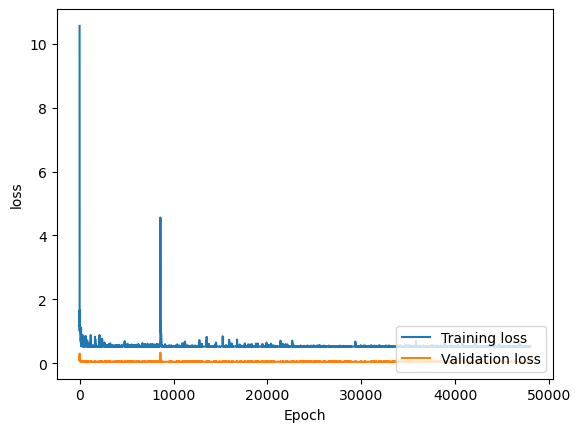

In [11]:
plt.plot(history["loss"], label="Training loss")
plt.plot(history["val_loss"], label="Validation loss")
plt.xlabel('Epoch')
plt.ylabel('loss')
#plt.ylim([0, 1.2])
plt.legend(loc='lower right')

#val_loss = validation_step(input_para_val, input_phase_space_val, output_val)

In [12]:
trans_M_pred = model.predict(input_para_val)

print("Predicted transfer matrix:")
print(np.array2string(trans_M_pred[0], suppress_small=True))#, precision=6

phase_space_pred = tf.einsum("bij,bpj->bpi", trans_M_pred, input_phase_space_val)

phase_space_pred = tf.reshape(phase_space_pred, (-1, 6))
phase_space_pred = phase_space_pred.numpy()

ML_result_df = pd.DataFrame(phase_space_pred, columns=fixfield_phase_space_headers)
#fixfield_headers =  ["m0 [MeV*c^-2]", "q [unit charge]", "x [m]", "y [m]", "z [m]", "Ptot [MeV/c]", "ux []", "uy []", "uz []"]
#ML_result_df["m0 [MeV*c^-2]"] = input_df["m0 [MeV*c^-2]"] 
#ML_result_df["q [unit charge]"] = input_df["q [unit charge]"] 
#ML_result_df["Ptot [MeV/c]"] = input_df["Ptot [MeV/c]"] 

out_name = "ML_FFA_sample/FFA_ML_trans_matrix_result.dat"
    
print("writing to file : "+out_name)

writeFile(ML_result_df, out_name)

1/1 [==============================] - 0s 79ms/step
Predicted transfer matrix:
[[ 0.11236353  1.5737462  -0.00633479  5.4639125   0.6167699  -0.16571309]
 [-0.00770338 -1.7654793   0.00820279  0.00165859  0.00274235 -0.00973488]
 [ 0.00283496  1.341332    0.5532905   0.00053638  0.00001128  7.0476956 ]
 [-0.0844612  -0.1917778  -0.00051381 -0.18007256  0.07775812 -0.02004721]
 [-0.13767095 -1.1434873  -0.01594998 -2.361798    0.85466415 -0.10472101]
 [-0.01558097  0.7553797  -0.02411931  0.00197536 -0.00251906  0.74469453]]
writing to file : ML_FFA_sample/FFA_ML_trans_matrix_result.dat


140625
pred data
[[ 5.62871754e-01 -5.66491508e-07  3.27576995e-02  6.84100315e-02
   8.65900397e-01  1.40210222e-02]
 [ 6.16050780e-01  2.42929463e-03 -1.50818944e-01  8.64509419e-02
   8.68573964e-01 -4.69142757e-03]
 [ 5.98381460e-01  4.16506315e-03  1.35676295e-01  9.03164223e-02
   8.72516215e-01  1.03119202e-02]
 ...
 [ 9.30752814e-01  2.93574575e-03 -1.23395547e-01  1.15061864e-01
   9.06894743e-01 -1.49662513e-02]
 [ 8.85436654e-01  1.74616219e-03  4.75526005e-02  1.01863980e-01
   9.12769318e-01 -1.56490086e-03]
 [ 7.60221779e-01  2.99692457e-03 -7.93144107e-04  1.08346365e-01
   9.19556022e-01 -8.37683491e-03]]
val data
[[ 0.1982683   0.          0.04134328  0.01906218  0.9995682   0.02236005]
 [ 0.2996506   0.         -0.2113335   0.04194485  0.9991152  -0.00307301]
 [ 0.2897762   0.          0.1956625   0.04833021  0.9987554   0.01231858]
 ...
 [ 1.199125    0.         -0.1792084   0.1519496   0.9882387  -0.01719233]
 [ 1.160653    0.          0.07060928  0.1373023   0.9905

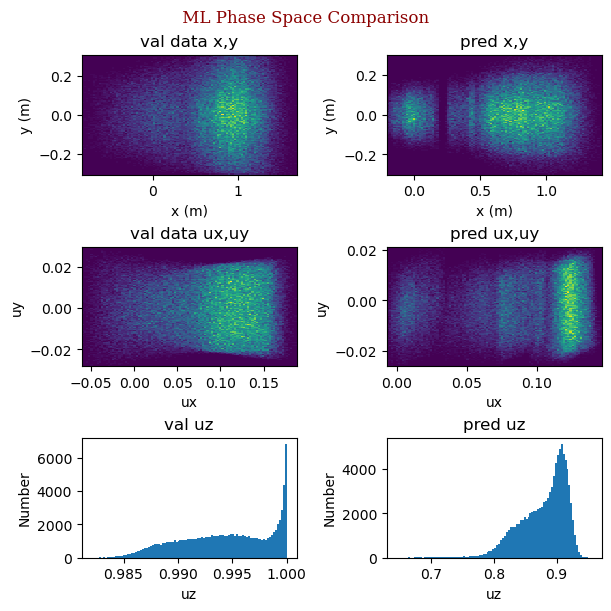

In [13]:
print(len(phase_space_pred))
print("pred data")
print(phase_space_pred)
print("val data")
unpack_output_val = output_val.reshape((-1, 6))
print(unpack_output_val)

#unpack_output_val = output_val*output_norm_array
#part_num = len(part_lost_pred)
#pred_survive_index = []
val_survive_index = []
same_survive_thresh = 0.5
    
#val_survive_index = np.asarray(val_survive_index, dtype=np.intp)
unpack_output_val = unpack_output_val[val_survive_index]
phase_space_pred_survive = phase_space_pred[val_survive_index]

#print("val surving particle num : "+str(len(val_survive_index))+", pred surving particle num : "+str(len(pred_survive_index))+", diff : "+str(100*(len(val_survive_index)-len(pred_survive_index))/len(val_survive_index))+" %")
print("val surving particle num : "+str(len(val_survive_index)))
      
fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(6., 6.), \
                                layout="constrained")
# add an artist, in this case a nice label in the middle...
Ttl = " ML Phase Space Comparison "

fig.suptitle(Ttl, fontdict=font)

axs[0, 0].set_title('val data x,y')
axs[0, 0].hist2d(unpack_output_val[:,0], unpack_output_val[:,2], bins=100)
axs[0, 0].set_xlabel('x (m)')
axs[0, 0].set_ylabel('y (m)')

axs[0, 1].set_title('pred x,y')
axs[0, 1].hist2d(phase_space_pred_survive[:,0], phase_space_pred_survive[:,2], bins=100)
axs[0, 1].set_xlabel('x (m)')
axs[0, 1].set_ylabel('y (m)')

axs[1, 0].set_title('val data ux,uy')
axs[1, 0].hist2d(unpack_output_val[:,3], unpack_output_val[:,5], bins=100)
axs[1, 0].set_xlabel('ux')
axs[1, 0].set_ylabel('uy')

axs[1, 1].set_title('pred ux,uy')
axs[1, 1].hist2d(phase_space_pred_survive[:,3], phase_space_pred_survive[:,5], bins=100)
axs[1, 1].set_xlabel('ux')
axs[1, 1].set_ylabel('uy')

axs[2, 0].set_title('val uz')
axs[2, 0].hist(unpack_output_val[:,4], 100)
axs[2, 0].set_yscale('linear')
axs[2, 0].set_xlabel('uz')
axs[2, 0].set_ylabel('Number')

axs[2, 1].set_title('pred uz')
axs[2, 1].hist(phase_space_pred_survive[:,4], 100)
axs[2, 1].set_yscale('linear')
axs[2, 1].set_xlabel('uz')
axs[2, 1].set_ylabel('Number')

plt.show()

In [14]:
#=================================================================================
#basic architechture with LhARA style 
#=================================================================================

In [83]:
#convert fixfield particle data to LhARA style data

input_fixfield_df = input_df[fixfield_headers]
input_fixfield_np_lst = input_fixfield_df.to_numpy()

output_df = pd.read_csv(FFA_ML_output, sep = "\s+", skiprows=1, names=fixfield_headers) #output for ML contains only particle data in form of fixfield
output_fixfield_np_lst = output_df.to_numpy()

fixfield_col_num = len(fixfield_headers)

input_fixfield_train = np.zeros((FFA_type_num,sample_part_num_per_FFA,fixfield_col_num), dtype="float32") #training data
output_fixfield_train = np.zeros((FFA_type_num,sample_part_num_per_FFA,fixfield_col_num), dtype="float32")

input_fixfield_val = np.zeros((FFA_type_num,sample_part_num_per_FFA,fixfield_col_num), dtype="float32") #validation data
output_fixfield_val = np.zeros((FFA_type_num,sample_part_num_per_FFA,fixfield_col_num), dtype="float32")


for FFA_num in range(0, FFA_type_num):
    for i in range(0,sample_part_num_per_FFA):
        
        part_num = FFA_num*sample_part_num_per_FFA+i
    
        input_fixfield_train[FFA_num][i] = input_fixfield_np_lst[2*part_num]
        input_fixfield_val[FFA_num][i] = input_fixfield_np_lst[2*part_num+1]
    
        output_fixfield_train[FFA_num][i] = output_fixfield_np_lst[2*part_num]
        output_fixfield_val[FFA_num][i] = output_fixfield_np_lst[2*part_num+1]
    

output_fixfield_val_corrected = np.zeros_like(output_fixfield_val)
output_fixfield_train_corrected = np.zeros_like(output_fixfield_train)

output_lost_val_corrected = np.zeros(output_fixfield_val.shape[:2], dtype=np.float32)
output_lost_train_corrected = np.zeros(output_fixfield_val.shape[:2], dtype=np.float32)

for i in range(FFA_type_num):

    reconstructed, survive = reconstruct_output(input_fixfield_val[i],output_fixfield_val[i])
    output_fixfield_val_corrected[i] = reconstructed
    output_lost_val_corrected[i] = survive.astype(np.float32)

    reconstructed, survive = reconstruct_output(input_fixfield_train[i],output_fixfield_train[i])
    output_fixfield_train_corrected[i] = reconstructed
    output_lost_train_corrected[i] = survive.astype(np.float32)

input_LhARA_train = fixfield_to_LhARA(input_fixfield_train)
output_LhARA_train = fixfield_to_LhARA(output_fixfield_train_corrected)

input_LhARA_val = fixfield_to_LhARA(input_fixfield_val)
output_LhARA_val = fixfield_to_LhARA(output_fixfield_val_corrected)

print("input_fixfield_train shape")
print(input_fixfield_train.shape)
print("input_LhARA_train shape")
print(input_LhARA_train.shape)
print("input_LhARA_train")
print(input_LhARA_train[3][1440])
print("output_LhARA_val")
print(output_LhARA_val[3][1440])
print("lost_count_train : "+str(lost_count_train)+", lost_count_val : "+str(lost_count_val))

input_LhARA_plot = input_LhARA_val.reshape((-1, 6))[val_survive_index]
output_LhARA_plot = output_LhARA_val.reshape((-1, 6))[val_survive_index]

fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(6., 6.), \
                                layout="constrained")
# add an artist, in this case a nice label in the middle...

Ttl = "LhARA style input sample"

fig.suptitle(Ttl, fontdict=font)

axs[0, 0].set_title('input val data x,y')
axs[0, 0].hist2d(input_LhARA_plot[:,0], input_LhARA_plot[:,2], bins=100)
axs[0, 0].set_xlabel('x (cm)')
axs[0, 0].set_ylabel('y (cm)')

axs[0, 1].set_title('output val data x,y')
axs[0, 1].hist2d(output_LhARA_plot[:,0], output_LhARA_plot[:,2], bins=100)
axs[0, 1].set_xlabel('x (cm)')
axs[0, 1].set_ylabel('y (cm)')

axs[1, 0].set_title('input val data ux,uy')
axs[1, 0].hist2d(input_LhARA_plot[:,1], input_LhARA_plot[:,3], bins=100)
axs[1, 0].set_xlabel('ux')
axs[1, 0].set_ylabel('uy')

axs[1, 1].set_title('output val ux,uy')
axs[1, 1].hist2d(output_LhARA_plot[:,1], output_LhARA_plot[:,3], bins=100)
axs[1, 1].set_xlabel('ux')
axs[1, 1].set_ylabel('uy')

axs[2, 0].set_title('input val z')
axs[2, 0].hist(input_LhARA_plot[:,4], 100)
axs[2, 0].set_yscale('linear')
axs[2, 0].set_xlabel('z (cm)')
axs[2, 0].set_ylabel('Number')

axs[2, 1].set_title('output pred z')
axs[2, 1].hist(output_LhARA_plot[:,4], 100)
axs[2, 1].set_yscale('linear')
axs[2, 1].set_xlabel('z (cm)')
axs[2, 1].set_ylabel('Number')

plt.show()

ValueError: No momentum match for output particle 7. Mass=100.0, momentum=3547.486083984375, closest difference=0.64599609375

In [16]:
print(input_LhARA_train.dtype)
print(input_LhARA_train.shape)
print(input_LhARA_val.dtype)
print(input_LhARA_val.shape)
print("output_LhARA_val")
print(output_LhARA_val[0][1440])

float32
(15, 9375, 6)
float32
(15, 9375, 6)
output_LhARA_val
[0.5013248  0.07725809 0.2329986  0.01473044 0.         4.433574  ]


In [17]:
class TransferMatrixModel(tf.keras.Model):

    def __init__(self):
        super().__init__()

        self.network = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(17,)),

            tf.keras.layers.Dense(128, activation="tanh"),
            tf.keras.layers.Dense(128, activation="tanh"),
            tf.keras.layers.Dense(128, activation="tanh"),

            # Output 36 matrix elements
            tf.keras.layers.Dense(36)
        ])

    def call(self, field):

        # field:
        # (N_fields, 17)

        matrix_elements = self.network(field)

        # matrix_elements:
        # (N_fields, 36)

        M = tf.cast(tf.reshape(matrix_elements,(-1, 6, 6)), dtype=tf.float32)

        # M:
        # (N_fields, 6, 6)

        return M

In [18]:
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
LhARA_model = TransferMatrixModel()

dummy_field = tf.zeros((1, 17))
_ = LhARA_model(dummy_field)

LhARA_model.summary()

@tf.function
def LhARA_train_step(field, phase_space_before, phase_space_after, particle_weights):

    with tf.GradientTape() as tape:

        M = LhARA_model(field)
        #phase_space_before_tensor = tf.cast(phase_space_before, dtype=tf.float32)
        phase_space_pred = tf.einsum("bij,bpj->bpi", M, phase_space_before)

        particle_loss = tf.reduce_mean(tf.square(phase_space_pred - phase_space_after), axis=-1)
        weighted_loss = particle_loss * particle_weights

        loss_per_setting = (tf.reduce_sum(weighted_loss, axis=1)/tf.maximum(tf.reduce_sum(particle_weights, axis=1),1.0))
        loss = tf.reduce_sum(loss_per_setting)

    gradients = tape.gradient(loss, LhARA_model.trainable_variables)
    optimizer.apply_gradients(zip(gradients,LhARA_model.trainable_variables))

    return loss

@tf.function
def LhARA_validation_step(field, phase_space_before, phase_space_after):
    # One transfer matrix per field configuration
    M = LhARA_model(field, training=False)

    # Apply the same matrix to every particle in each group
    phase_space_pred = tf.einsum("bij,bpj->bpi", M, phase_space_before)

    # Same loss as training
    loss = tf.reduce_mean(tf.square(phase_space_pred - phase_space_after))

    return loss

Model: "transfer_matrix_model_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sequential_1 (Sequential)   (None, 36)                39972     
                                                                 
Total params: 39,972
Trainable params: 39,972
Non-trainable params: 0
_________________________________________________________________


In [19]:
history = {"loss": [], "val_loss": []}
#train the model
num_epochs = 48000
#Not worried about memory or local minima
batchSize = len(input_phase_space_train[0])

starttime = time.time()
for epoch in range(num_epochs):
    epoch_losses = []
    val_losses = []

    loss = LhARA_train_step(input_para_train, input_LhARA_train, output_LhARA_train, output_lost_train)
    val_loss = LhARA_validation_step(input_para_val, input_LhARA_val, output_LhARA_val)
    
    epoch_losses.append(float(loss.numpy()))
    epoch_loss = sum(epoch_losses) / len(epoch_losses)
    
    val_losses.append(float(val_loss.numpy()))
    epoch_val_loss = sum(val_losses) / len(val_losses)
    
    history["loss"].append(epoch_loss)
    history["val_loss"].append(epoch_val_loss)

    if epoch % 1000 == 0:
        print(f"Epoch {epoch}: loss = {loss.numpy()}, "
            f"val_loss: {epoch_val_loss:.6e}")

timepass = time.time()-starttime
print("training completed in "+str(timepass)+" sec. for "+str(num_epochs)+" epochs "+str(timepass/num_epochs)+"  sec. per epoch")

full_model_filename = 'FFA_LhARA_trans_matrix_ML'
saved_model_directory = 'ML_FFA_sample'

model_filename = os.path.join(saved_model_directory, full_model_filename)
model.save(model_filename)

Epoch 0: loss = 143.57272338867188, val_loss: 6.925383e-01
Epoch 1000: loss = 0.1535196602344513, val_loss: 2.276716e-02
Epoch 2000: loss = 0.13140995800495148, val_loss: 2.806136e-02
Epoch 3000: loss = 0.2315320074558258, val_loss: 1.972433e-02
Epoch 4000: loss = 0.09175460040569305, val_loss: 1.720521e-02
Epoch 5000: loss = 0.08593522012233734, val_loss: 1.938404e-02
Epoch 6000: loss = 0.08329794555902481, val_loss: 2.109689e-02
Epoch 7000: loss = 0.08258813619613647, val_loss: 2.130689e-02
Epoch 8000: loss = 0.08043603599071503, val_loss: 1.942557e-02
Epoch 9000: loss = 0.07904722541570663, val_loss: 1.910252e-02
Epoch 10000: loss = 0.07971600443124771, val_loss: 1.994181e-02
Epoch 11000: loss = 0.07782607525587082, val_loss: 2.010917e-02
Epoch 12000: loss = 0.07823801040649414, val_loss: 2.001515e-02
Epoch 13000: loss = 0.08798209577798843, val_loss: 1.908961e-02
Epoch 14000: loss = 0.07942728698253632, val_loss: 1.958175e-02
Epoch 15000: loss = 0.08945252746343613, val_loss: 2.229

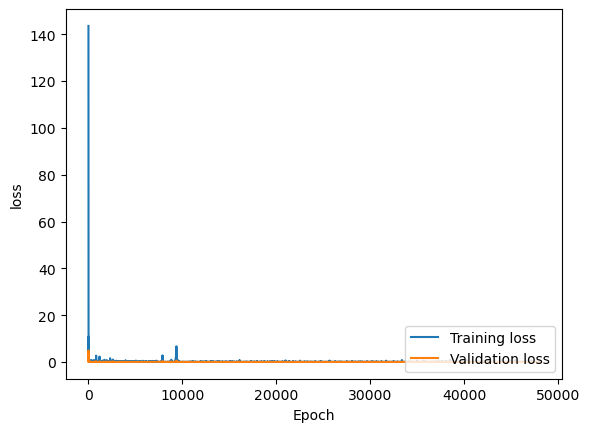

In [20]:
plt.plot(history["loss"], label="Training loss")
plt.plot(history["val_loss"], label="Validation loss")
plt.xlabel('Epoch')
plt.ylabel('loss')
#plt.ylim([0, 1.2])
plt.legend(loc='lower right')

#val_loss = validation_step(input_para_val, input_phase_space_val, output_val)

In [21]:
trans_M_pred = LhARA_model.predict(input_para_val)

print("Predicted transfer matrix:")
print(np.array2string(trans_M_pred[0], precision=6, suppress_small=True))#

phase_space_pred = tf.einsum("bij,bpj->bpi", trans_M_pred, input_LhARA_val)

phase_space_pred = tf.reshape(phase_space_pred, (-1, 6))
phase_space_pred = phase_space_pred.numpy()

ML_result_df = pd.DataFrame(phase_space_pred, columns=fixfield_phase_space_headers)
#fixfield_headers =  ["m0 [MeV*c^-2]", "q [unit charge]", "x [m]", "y [m]", "z [m]", "Ptot [MeV/c]", "ux []", "uy []", "uz []"]
#ML_result_df["m0 [MeV*c^-2]"] = input_df["m0 [MeV*c^-2]"] 
#ML_result_df["q [unit charge]"] = input_df["q [unit charge]"] 
#ML_result_df["Ptot [MeV/c]"] = input_df["Ptot [MeV/c]"] 

out_name = "ML_FFA_sample/FFA_ML_trans_matrix_result.dat"
    
print("writing to file : "+out_name)

writeFile(ML_result_df, out_name)

1/1 [==============================] - 0s 43ms/step
Predicted transfer matrix:
[[ 0.254751  8.314213  0.004483 -0.115857  0.067592  0.147098]
 [-0.076112  0.113312  0.000793 -0.016733 -0.459422  0.022532]
 [ 0.001881  0.06695   0.609617  7.742293  3.226429  0.001942]
 [-0.003059 -0.003241 -0.018611  0.770884  0.829362  0.003617]
 [ 0.002885  0.006262 -0.000447  0.004747  1.428029 -0.004439]
 [-0.002711  0.226463 -0.003048 -0.032808 -2.612272  1.00488 ]]
writing to file : ML_FFA_sample/FFA_ML_trans_matrix_result.dat


140625
pred data
[[ 0.44796553  0.06745924  0.04151614  0.03050429 -0.01516951  3.5395331 ]
 [ 0.5078736   0.08785718 -0.15885241  0.0082725  -0.01598988  3.56028   ]
 [ 0.48621467  0.09178289  0.15625353  0.02446472 -0.01620545  3.580459  ]
 ...
 [ 1.2869385   0.1875597  -0.11949867  0.0106302  -0.02909678  6.526131  ]
 [ 1.2405636   0.17311707  0.06001092  0.02617114 -0.02860478  6.5340104 ]
 [ 1.1087819   0.17927513  0.00868605  0.01827937 -0.0290647   6.5307093 ]]
val data
[[ 1.9826829e-01  1.9062180e-02  4.1343279e-02  2.2360049e-02
   0.0000000e+00  3.5255165e+00]
 [ 2.9965061e-01  4.1944850e-02 -2.1133350e-01 -3.0730129e-03
   0.0000000e+00  3.5416019e+00]
 [ 2.8977621e-01  4.8330210e-02  1.9566250e-01  1.2318580e-02
   0.0000000e+00  3.5632346e+00]
 ...
 [ 1.1991251e+00  1.5194960e-01 -1.7920840e-01 -1.7192330e-02
   0.0000000e+00  6.5043917e+00]
 [ 1.1606530e+00  1.3730229e-01  7.0609279e-02  4.5110532e-03
   0.0000000e+00  6.5135579e+00]
 [ 9.9062508e-01  1.4036900e-01  3.052

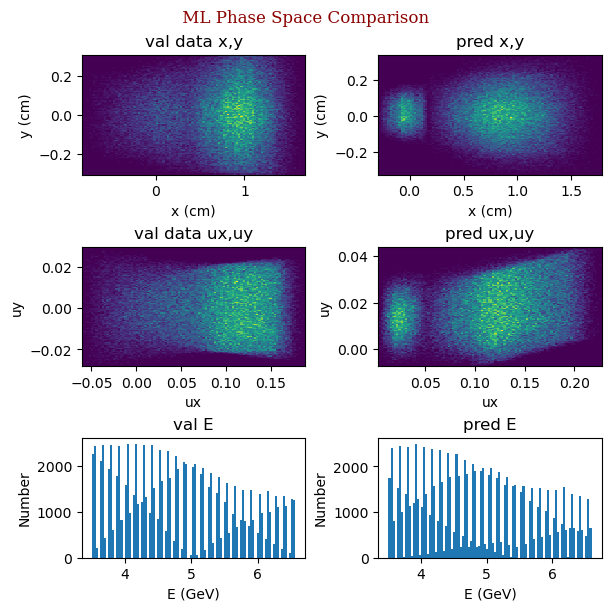

In [22]:
print(len(phase_space_pred))
print("pred data")
print(phase_space_pred)
print("val data")
unpack_output_val = output_LhARA_val.reshape((-1, 6))
print(unpack_output_val)

#unpack_output_val = output_val*output_norm_array
#part_num = len(part_lost_pred)
#pred_survive_index = []
val_survive_index = []
same_survive_thresh = 0.5
output_lost_val_re = output_lost_val.reshape(-1)
for i in range(0,part_num):
    #if (phase_space_pred[i][3]+phase_space_pred[i][4]+phase_space_pred[i][5])<1e-1:
        #pred_survive_index.append(i)
    if output_lost_val_re[i]>same_survive_thresh:
        val_survive_index.append(i)
    
#val_survive_index = np.asarray(val_survive_index, dtype=np.intp)
unpack_output_val = unpack_output_val[val_survive_index]
phase_space_pred_survive = phase_space_pred[val_survive_index]

#print("val surving particle num : "+str(len(val_survive_index))+", pred surving particle num : "+str(len(pred_survive_index))+", diff : "+str(100*(len(val_survive_index)-len(pred_survive_index))/len(val_survive_index))+" %")
print("val surving particle num : "+str(len(val_survive_index)))
      
fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(6., 6.), \
                                layout="constrained")
# add an artist, in this case a nice label in the middle...
Ttl = " ML Phase Space Comparison "

fig.suptitle(Ttl, fontdict=font)

axs[0, 0].set_title('val data x,y')
axs[0, 0].hist2d(unpack_output_val[:,0], unpack_output_val[:,2], bins=100)
axs[0, 0].set_xlabel('x (cm)')
axs[0, 0].set_ylabel('y (cm)')

axs[0, 1].set_title('pred x,y')
axs[0, 1].hist2d(phase_space_pred_survive[:,0], phase_space_pred_survive[:,2], bins=100)
axs[0, 1].set_xlabel('x (cm)')
axs[0, 1].set_ylabel('y (cm)')

axs[1, 0].set_title('val data ux,uy')
axs[1, 0].hist2d(unpack_output_val[:,1], unpack_output_val[:,3], bins=100)
axs[1, 0].set_xlabel('ux')
axs[1, 0].set_ylabel('uy')

axs[1, 1].set_title('pred ux,uy')
axs[1, 1].hist2d(phase_space_pred_survive[:,1], phase_space_pred_survive[:,3], bins=100)
axs[1, 1].set_xlabel('ux')
axs[1, 1].set_ylabel('uy')

axs[2, 0].set_title('val E')
axs[2, 0].hist(unpack_output_val[:,5], 100)
axs[2, 0].set_yscale('linear')
axs[2, 0].set_xlabel('E (GeV)')
axs[2, 0].set_ylabel('Number')

axs[2, 1].set_title('pred E')
axs[2, 1].hist(phase_space_pred_survive[:,5], 100)
axs[2, 1].set_yscale('linear')
axs[2, 1].set_xlabel('E (GeV)')
axs[2, 1].set_ylabel('Number')

plt.show()

In [23]:
#=================================================================================
#basic architechture with LhARA style and invariant energy
#=================================================================================

In [24]:
class TransferMatrixModel_E_invar(tf.keras.Model):

    def __init__(self):
        super().__init__()

        self.network = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(17,)),

            tf.keras.layers.Dense(128, activation="tanh"),
            tf.keras.layers.Dense(128, activation="tanh"),
            tf.keras.layers.Dense(128, activation="tanh"),

            # Output 25 matrix elements
            tf.keras.layers.Dense(30)#only 5X6 part so that the energy is untouched
        ])

    def call(self, field):

        REDUCED_DIM = 5
        # field:
        # (N_fields, 17)

        matrix_elements = self.network(field)

        A = tf.cast(tf.reshape(matrix_elements,(-1, 5, 6)), dtype=tf.float32)

        # Add a fixed last column: [0, 0, 0, 0, 0, 1]^T
        #top = tf.keras.layers.Lambda(lambda a: tf.concat([a, tf.zeros((tf.shape(a)[0], REDUCED_DIM, 1))], axis=2))(A)
        
        # Add a fixed last row: [0, 0, 0, 0, 0, 1]
        bottom = tf.keras.layers.Lambda(lambda a: tf.tile(tf.constant([[[0., 0., 0., 0., 0., 1.]]]), [tf.shape(a)[0], 1, 1]))(A)
        
        M = tf.keras.layers.Concatenate(axis=1, name="transfer_matrix")([A, bottom])

        return M

In [25]:
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
LhARA_E_invar_model = TransferMatrixModel_E_invar()

dummy_field = tf.zeros((1, 17))
_ = LhARA_E_invar_model(dummy_field)

LhARA_E_invar_model.summary()

@tf.function
def LhARA_E_invar_train_step(field, phase_space_before, phase_space_after, particle_weights):

    with tf.GradientTape() as tape:

        M = LhARA_E_invar_model(field)
        #phase_space_before_tensor = tf.cast(phase_space_before, dtype=tf.float32)
        phase_space_pred = tf.einsum("bij,bpj->bpi", M, phase_space_before)

        particle_loss = tf.reduce_mean(tf.square(phase_space_pred - phase_space_after), axis=-1)
        weighted_loss = particle_loss * particle_weights

        loss_per_setting = (tf.reduce_sum(weighted_loss, axis=1)/tf.maximum(tf.reduce_sum(particle_weights, axis=1),1.0))
        loss = tf.reduce_sum(loss_per_setting)

    gradients = tape.gradient(loss, LhARA_E_invar_model.trainable_variables)
    optimizer.apply_gradients(zip(gradients,LhARA_E_invar_model.trainable_variables))

    return loss

@tf.function
def LhARA_E_invar_validation_step(field, phase_space_before, phase_space_after):
    # One transfer matrix per field configuration
    M = LhARA_E_invar_model(field, training=False)

    # Apply the same matrix to every particle in each group
    phase_space_pred = tf.einsum("bij,bpj->bpi", M, phase_space_before)

    # Same loss as training
    loss = tf.reduce_mean(tf.square(phase_space_pred - phase_space_after))

    return loss

Model: "transfer_matrix_model_e_invar"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sequential_2 (Sequential)   (None, 30)                39198     
                                                                 
Total params: 39,198
Trainable params: 39,198
Non-trainable params: 0
_________________________________________________________________


In [26]:
history = {"loss": [], "val_loss": []}
#train the model
num_epochs = 48000
#Not worried about memory or local minima
batchSize = len(input_phase_space_train[0])

starttime = time.time()
for epoch in range(num_epochs):
    epoch_losses = []
    val_losses = []

    loss = LhARA_E_invar_train_step(input_para_train, input_LhARA_train, output_LhARA_train, output_lost_train)
    val_loss = LhARA_E_invar_validation_step(input_para_val, input_LhARA_val, output_LhARA_val)
    
    epoch_losses.append(float(loss.numpy()))
    epoch_loss = sum(epoch_losses) / len(epoch_losses)
    
    val_losses.append(float(val_loss.numpy()))
    epoch_val_loss = sum(val_losses) / len(val_losses)
    
    history["loss"].append(epoch_loss)
    history["val_loss"].append(epoch_val_loss)

    if epoch % 1000 == 0:
        print(f"Epoch {epoch}: loss = {loss.numpy()}, "
            f"val_loss: {epoch_val_loss:.6e}")

timepass = time.time()-starttime
print("training completed in "+str(timepass)+" sec. for "+str(num_epochs)+" epochs "+str(timepass/num_epochs)+"  sec. per epoch")

full_model_filename = 'FFA_LhARA_E_invar_trans_matrix_ML'
saved_model_directory = 'ML_FFA_sample'

model_filename = os.path.join(saved_model_directory, full_model_filename)
model.save(model_filename)

Epoch 0: loss = 223.67662048339844, val_loss: 1.391867e+00
Epoch 1000: loss = 0.12098319828510284, val_loss: 1.792376e-02
Epoch 2000: loss = 0.10515207052230835, val_loss: 2.182377e-02
Epoch 3000: loss = 0.11519540846347809, val_loss: 2.393045e-02
Epoch 4000: loss = 0.10330374538898468, val_loss: 2.060278e-02
Epoch 5000: loss = 0.08440177142620087, val_loss: 1.871503e-02
Epoch 6000: loss = 0.10858523100614548, val_loss: 1.882404e-02
Epoch 7000: loss = 0.08573319762945175, val_loss: 1.929731e-02
Epoch 8000: loss = 0.10162361711263657, val_loss: 1.771745e-02
Epoch 9000: loss = 0.07990546524524689, val_loss: 1.896252e-02
Epoch 10000: loss = 0.0784049779176712, val_loss: 1.968332e-02
Epoch 11000: loss = 0.07976406812667847, val_loss: 1.959794e-02
Epoch 12000: loss = 0.08564359694719315, val_loss: 2.118394e-02
Epoch 13000: loss = 0.08591760694980621, val_loss: 2.281685e-02
Epoch 14000: loss = 0.08496510982513428, val_loss: 1.978724e-02
Epoch 15000: loss = 0.07845744490623474, val_loss: 2.01

In [49]:
trans_M_pred = LhARA_E_invar_model.predict(input_para_val)

print("Predicted transfer matrix:")
print(np.array2string(trans_M_pred[0], precision=6, suppress_small=True))#
phase_space_pred = tf.einsum("bij,bpj->bpi", trans_M_pred, input_LhARA_val)

phase_space_pred = tf.reshape(phase_space_pred, (-1, 6))
phase_space_pred = phase_space_pred.numpy()

ML_result_df = pd.DataFrame(phase_space_pred, columns=fixfield_phase_space_headers)
#fixfield_headers =  ["m0 [MeV*c^-2]", "q [unit charge]", "x [m]", "y [m]", "z [m]", "Ptot [MeV/c]", "ux []", "uy []", "uz []"]
#ML_result_df["m0 [MeV*c^-2]"] = input_df["m0 [MeV*c^-2]"] 
#ML_result_df["q [unit charge]"] = input_df["q [unit charge]"] 
#ML_result_df["Ptot [MeV/c]"] = input_df["Ptot [MeV/c]"] 

out_name = "ML_FFA_sample/FFA_ML_trans_matrix_result.dat"
    
print("writing to file : "+out_name)

writeFile(ML_result_df, out_name)

1/1 [==============================] - 0s 16ms/step
Predicted transfer matrix:
[[ 0.185153  8.923123 -0.009199 -0.597513 -1.215534  0.1111  ]
 [-0.079623  0.095338 -0.005602 -0.019866 -1.43951   0.012115]
 [ 0.008645 -0.01696   0.60893   8.258988  1.443081 -0.006921]
 [ 0.000371 -0.004241 -0.030545  0.797104  3.464747 -0.000928]
 [-0.000506  0.008852 -0.008654  0.006145  0.712044  0.000396]
 [ 0.        0.        0.        0.        0.        1.      ]]
writing to file : ML_FFA_sample/FFA_ML_trans_matrix_result.dat


In [57]:
start_index = 0
end_index = 15
part_per_index = 9375
val_survive_index_slice = []
for i in range(start_index*part_per_index,end_index*part_per_index):#only get the surviving part index for chosen FFAs
    if output_lost_val_re[i]>same_survive_thresh:
        val_survive_index_slice.append(i)


print(unpack_output_val.shape)
print(phase_space_pred_survive.shape)
print(len(val_survive_index))
print(len(val_survive_index_slice))

(100022, 6)
(100022, 6)
100022
100023


140625
pred data
[[ 2.97701418e-01  3.16073820e-02  2.21678838e-02  1.76505074e-02
   2.93097692e-03  3.52551627e+00]
 [ 3.95223916e-01  5.22711053e-02 -1.96045518e-01 -6.68167835e-03
   2.67713913e-03  3.54160166e+00]
 [ 3.60681921e-01  5.48462719e-02  1.31615028e-01  7.58390967e-03
   1.17278786e-03  3.56323409e+00]
 ...
 [ 1.14299130e+00  1.24110132e-01 -1.75181359e-01 -1.78971551e-02
   3.14992829e-03  6.50439119e+00]
 [ 1.08926260e+00  1.11501366e-01  4.57708165e-03 -1.82090863e-03
   2.62048864e-03  6.51355791e+00]
 [ 9.62675333e-01  1.16651833e-01 -4.69083451e-02 -1.00805350e-02
   2.37331563e-03  6.51039600e+00]]
val data
[[ 1.9826829e-01  1.9062180e-02  4.1343279e-02  2.2360049e-02
   0.0000000e+00  3.5255165e+00]
 [ 2.9965061e-01  4.1944850e-02 -2.1133350e-01 -3.0730129e-03
   0.0000000e+00  3.5416019e+00]
 [ 2.8977621e-01  4.8330210e-02  1.9566250e-01  1.2318580e-02
   0.0000000e+00  3.5632346e+00]
 ...
 [ 1.1991251e+00  1.5194960e-01 -1.7920840e-01 -1.7192330e-02
   0.00000

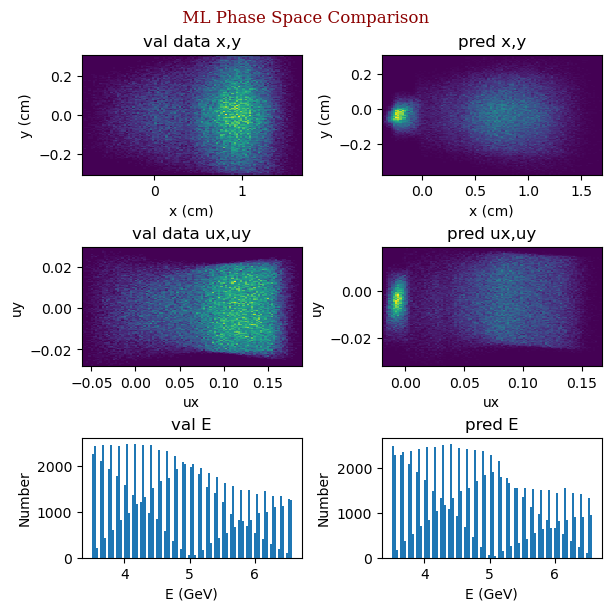

In [58]:
print(len(phase_space_pred))
print("pred data")
print(phase_space_pred)
print("val data")
unpack_output_val = output_LhARA_val.reshape((-1, 6))
print(unpack_output_val)

#unpack_output_val = output_val*output_norm_array
#part_num = len(part_lost_pred)
#pred_survive_index = []

same_survive_thresh = 0.5
    
#val_survive_index = np.asarray(val_survive_index, dtype=np.intp)
unpack_output_val = unpack_output_val[val_survive_index_slice]#val_survive_index_slice
phase_space_pred_survive = phase_space_pred[val_survive_index_slice]

#print("val surving particle num : "+str(len(val_survive_index))+", pred surving particle num : "+str(len(pred_survive_index))+", diff : "+str(100*(len(val_survive_index)-len(pred_survive_index))/len(val_survive_index))+" %")
print("val surving particle num : "+str(len(val_survive_index)))
      
fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(6., 6.), \
                                layout="constrained")
# add an artist, in this case a nice label in the middle...
Ttl = " ML Phase Space Comparison "

fig.suptitle(Ttl, fontdict=font)

axs[0, 0].set_title('val data x,y')
axs[0, 0].hist2d(unpack_output_val[:,0], unpack_output_val[:,2], bins=100)
axs[0, 0].set_xlabel('x (cm)')
axs[0, 0].set_ylabel('y (cm)')

axs[0, 1].set_title('pred x,y')
axs[0, 1].hist2d(phase_space_pred_survive[:,0], phase_space_pred_survive[:,2], bins=100)
axs[0, 1].set_xlabel('x (cm)')
axs[0, 1].set_ylabel('y (cm)')

axs[1, 0].set_title('val data ux,uy')
axs[1, 0].hist2d(unpack_output_val[:,1], unpack_output_val[:,3], bins=100)
axs[1, 0].set_xlabel('ux')
axs[1, 0].set_ylabel('uy')

axs[1, 1].set_title('pred ux,uy')
axs[1, 1].hist2d(phase_space_pred_survive[:,1], phase_space_pred_survive[:,3], bins=100)
axs[1, 1].set_xlabel('ux')
axs[1, 1].set_ylabel('uy')

axs[2, 0].set_title('val E')
axs[2, 0].hist(unpack_output_val[:,5], 100)
axs[2, 0].set_yscale('linear')
axs[2, 0].set_xlabel('E (GeV)')
axs[2, 0].set_ylabel('Number')

axs[2, 1].set_title('pred E')
axs[2, 1].hist(phase_space_pred_survive[:,5], 100)
axs[2, 1].set_yscale('linear')
axs[2, 1].set_xlabel('E (GeV)')
axs[2, 1].set_ylabel('Number')

plt.show()

In [59]:
print(np.array2string(trans_M_pred[5], precision=6, suppress_small=True))#
tf.einsum("ij,j->i", trans_M_pred[5], np.array([3,5,1,4,5,12]))

[[ 0.634497 11.52353   0.002571  0.004355 -1.358201  0.20674 ]
 [-0.051123  0.344594 -0.003695  0.012881 -1.28785   0.023066]
 [-0.014494  0.030262  0.764636  9.499006  1.440627 -0.006955]
 [ 0.000997  0.002395  0.005007  1.002116  3.523376 -0.000857]
 [-0.002557  0.005483 -0.009417  0.006993  0.875311  0.000331]
 [ 0.        0.        0.        0.        0.        1.      ]]


<tf.Tensor: shape=(6,), dtype=float32, numpy=
array([55.23101  , -4.5450287, 45.98817  , 21.63504  ,  4.4188275,
       12.       ], dtype=float32)>

In [75]:
for i in range(10):

    print(
        "Input E:",
        input_LhARA_val[0][i][5],

        "Output E:",
        output_LhARA_val[0][i][5]
    )

Input E: 3.5255163 Output E: 3.5255165
Input E: 3.5416017 Output E: 3.541602
Input E: 3.563234 Output E: 3.5632346
Input E: 3.5035872 Output E: 3.5035872
Input E: 3.5076587 Output E: 3.5076587
Input E: 3.5433168 Output E: 3.5433164
Input E: 3.5482495 Output E: 3.5482495
Input E: 3.5116343 Output E: 3.5488954
Input E: 3.50543 Output E: 3.5054295
Input E: 3.5463052 Output E: 3.5463052


In [77]:
P_in_sorted = np.sort(P_in)
P_out_sorted = np.sort(P_out)

print(
    "Maximum sorted momentum difference:",
    np.max(np.abs(P_in_sorted - P_out_sorted))
)

print(
    "Mean sorted momentum difference:",
    np.mean(P_out_sorted - P_in_sorted)
)

Maximum sorted momentum difference: 69.71338
Mean sorted momentum difference: 6.206748


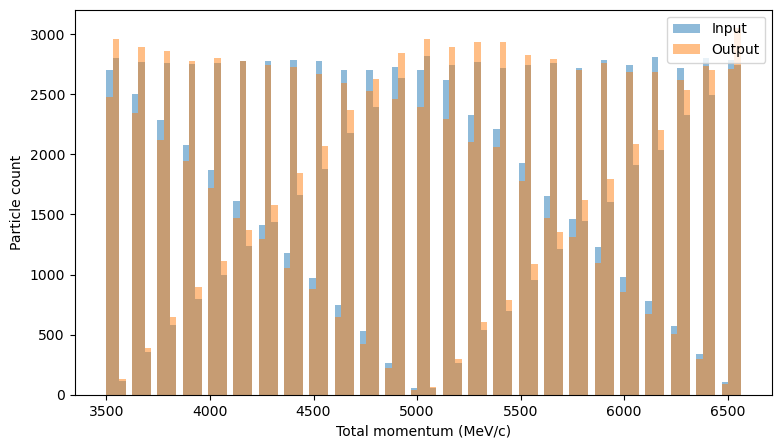

In [76]:
P_in = input_fixfield_val[:, :, 5].flatten()
P_out = output_fixfield_val[:, :, 5].flatten()

plt.figure(figsize=(9, 5))

plt.hist(P_in, bins=100, alpha=0.5, label="Input")
plt.hist(P_out, bins=100, alpha=0.5, label="Output")

plt.xlabel("Total momentum (MeV/c)")
plt.ylabel("Particle count")
plt.legend()
plt.show()

In [32]:
#=================================================================================
#Advanced architechture with LhARA style with delta value as data instead of raw values
#=================================================================================

In [33]:
base_matrix = tf.eye(6)

#just get the residual
class TransferMatrixModel_res_val(tf.keras.Model):

    def __init__(self):
        super().__init__()

        self.network = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(17,)),

            tf.keras.layers.Dense(128, activation="tanh"),
            tf.keras.layers.Dense(128, activation="tanh"),
            tf.keras.layers.Dense(128, activation="tanh"),

            tf.keras.layers.Dense(36)
        ])

    def call(self, field):

        # field:
        # (N_fields, 17)

        matrix_elements = self.network(field)

        M = tf.cast(tf.reshape(matrix_elements,(-1, 6, 6)), dtype=tf.float32)

        return M

In [34]:
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
LhARA_res_val_model = TransferMatrixModel_res_val()

dummy_field = tf.zeros((1, 17))
_ = LhARA_res_val_model(dummy_field)

LhARA_res_val_model.summary()

@tf.function
def LhARA_res_valtrain_step(field, phase_space_before, phase_space_after, particle_weights):

    with tf.GradientTape() as tape:

        M = LhARA_res_val_model(field)
        phase_space_after_residual = phase_space_after - tf.einsum("ij,bpj->bpi", base_matrix, phase_space_before)#calc residual of phase space
        phase_space_residual_pred = tf.einsum("bij,bpj->bpi", M, phase_space_before)

        particle_loss = tf.reduce_mean(tf.square(phase_space_residual_pred - phase_space_after_residual), axis=-1)
        weighted_loss = particle_loss * particle_weights

        loss_per_setting = (tf.reduce_sum(weighted_loss, axis=1)/tf.maximum(tf.reduce_sum(particle_weights, axis=1),1.0))
        loss = tf.reduce_sum(loss_per_setting)

    gradients = tape.gradient(loss, LhARA_res_val_model.trainable_variables)
    optimizer.apply_gradients(zip(gradients,LhARA_res_val_model.trainable_variables))

    return loss

@tf.function
def LhARA_res_val_validation_step(field, phase_space_before, phase_space_after):

    # One transfer matrix per field configuration
    M = LhARA_res_val_model(field, training=False)

    # Calculate residual phase space
    phase_space_after_residual = (phase_space_after - tf.einsum("ij,bpj->bpi", base_matrix, phase_space_before))

    # Predict residual phase space
    phase_space_residual_pred = tf.einsum("bij,bpj->bpi", M, phase_space_before)

    # Calculate validation loss
    loss = tf.reduce_mean(tf.square( phase_space_residual_pred - phase_space_after_residual))

    return loss

Model: "transfer_matrix_model_res_val"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sequential_3 (Sequential)   (None, 36)                39972     
                                                                 
Total params: 39,972
Trainable params: 39,972
Non-trainable params: 0
_________________________________________________________________


In [35]:
history = {"loss": [], "val_loss": []}
#train the model
num_epochs = 48000
#Not worried about memory or local minima
batchSize = len(input_phase_space_train[0])

starttime = time.time()
for epoch in range(num_epochs):
    epoch_losses = []
    val_losses = []

    loss = LhARA_res_valtrain_step(input_para_train, input_LhARA_train, output_LhARA_train, output_lost_train)
    val_loss = LhARA_res_val_validation_step(input_para_val, input_LhARA_val, output_LhARA_val)
    
    epoch_losses.append(float(loss.numpy()))
    epoch_loss = sum(epoch_losses) / len(epoch_losses)
    
    val_losses.append(float(val_loss.numpy()))
    epoch_val_loss = sum(val_losses) / len(val_losses)
    
    history["loss"].append(epoch_loss)
    history["val_loss"].append(epoch_val_loss)

    if epoch % 1000 == 0:
        print(f"Epoch {epoch}: loss = {loss.numpy()}, "
            f"val_loss: {epoch_val_loss:.6e}")

timepass = time.time()-starttime
print("training completed in "+str(timepass)+" sec. for "+str(num_epochs)+" epochs "+str(timepass/num_epochs)+"  sec. per epoch")

full_model_filename = 'FFA_LhARA_E_invar_trans_matrix_ML'
saved_model_directory = 'ML_FFA_sample'

model_filename = os.path.join(saved_model_directory, full_model_filename)
model.save(model_filename)

Epoch 0: loss = 96.31582641601562, val_loss: 1.024857e+00
Epoch 1000: loss = 0.11947812885046005, val_loss: 1.818661e-02
Epoch 2000: loss = 0.10733804851770401, val_loss: 1.786307e-02
Epoch 3000: loss = 0.13026274740695953, val_loss: 2.494117e-02
Epoch 4000: loss = 0.10941357165575027, val_loss: 2.048784e-02
Epoch 5000: loss = 0.09817303717136383, val_loss: 1.978774e-02
Epoch 6000: loss = 0.09294332563877106, val_loss: 2.306576e-02
Epoch 7000: loss = 0.07947833091020584, val_loss: 1.952630e-02
Epoch 8000: loss = 0.07933031022548676, val_loss: 2.052894e-02
Epoch 9000: loss = 0.08925040811300278, val_loss: 2.189649e-02
Epoch 10000: loss = 0.08039519190788269, val_loss: 2.018834e-02
Epoch 11000: loss = 0.08267947286367416, val_loss: 1.982105e-02
Epoch 12000: loss = 0.08414758741855621, val_loss: 2.351425e-02
Epoch 13000: loss = 0.07720234245061874, val_loss: 1.997758e-02
Epoch 14000: loss = 0.12595300376415253, val_loss: 2.829128e-02
Epoch 15000: loss = 0.09149905294179916, val_loss: 2.02

In [36]:
trans_M_pred = LhARA_res_val_model.predict(input_para_val) + base_matrix.numpy()

print("Predicted transfer matrix:")
print(np.array2string(trans_M_pred[0], precision=6, suppress_small=True))#
start_index = 0
end_index = 15
phase_space_pred = tf.einsum("bij,bpj->bpi", trans_M_pred, input_LhARA_val)#[start_index:end_index]

phase_space_pred = tf.reshape(phase_space_pred, (-1, 6))
phase_space_pred = phase_space_pred.numpy()

ML_result_df = pd.DataFrame(phase_space_pred, columns=fixfield_phase_space_headers)
#fixfield_headers =  ["m0 [MeV*c^-2]", "q [unit charge]", "x [m]", "y [m]", "z [m]", "Ptot [MeV/c]", "ux []", "uy []", "uz []"]
#ML_result_df["m0 [MeV*c^-2]"] = input_df["m0 [MeV*c^-2]"] 
#ML_result_df["q [unit charge]"] = input_df["q [unit charge]"] 
#ML_result_df["Ptot [MeV/c]"] = input_df["Ptot [MeV/c]"] 

out_name = "ML_FFA_sample/FFA_ML_trans_matrix_result.dat"
    
print("writing to file : "+out_name)

writeFile(ML_result_df, out_name)

1/1 [==============================] - 0s 37ms/step
Predicted transfer matrix:
[[ 0.235866  8.261154  0.00264  -0.121742  2.60398   0.142058]
 [-0.074747  0.099588 -0.002604 -0.011022 -1.576352  0.014016]
 [ 0.005368  0.059217  0.603395  7.646227 -0.214441 -0.00034 ]
 [ 0.005589 -0.005524 -0.021725  0.769919  1.747781 -0.006576]
 [-0.008302 -0.005306  0.008969 -0.010109  1.019817  0.007737]
 [-0.006188  0.206527 -0.004724 -0.034766  2.271948  1.002707]]
writing to file : ML_FFA_sample/FFA_ML_trans_matrix_result.dat


140625
pred data
[[ 4.28557307e-01  3.85204628e-02  3.33421268e-02 -3.69707309e-03
   2.43919529e-02  3.53192258e+00]
 [ 4.92214799e-01  5.79787791e-02 -1.65449783e-01 -2.82541737e-02
   2.70308163e-02  3.55317593e+00]
 [ 4.70955908e-01  6.11517131e-02  1.45789608e-01 -1.33469645e-02
   2.91121919e-02  3.57313108e+00]
 ...
 [ 1.26762807e+00  1.34905159e-01 -1.32518724e-01 -5.40355556e-02
   4.97427471e-02  6.50936222e+00]
 [ 1.22273183e+00  1.22463107e-01  4.30933684e-02 -3.74279208e-02
   4.85275835e-02  6.51899433e+00]
 [ 1.09201598e+00  1.27291754e-01 -7.03975139e-03 -4.61562574e-02
   5.00119291e-02  6.51474380e+00]]
val data
[[ 1.9826829e-01  1.9062180e-02  4.1343279e-02  2.2360049e-02
   0.0000000e+00  3.5255165e+00]
 [ 2.9965061e-01  4.1944850e-02 -2.1133350e-01 -3.0730129e-03
   0.0000000e+00  3.5416019e+00]
 [ 2.8977621e-01  4.8330210e-02  1.9566250e-01  1.2318580e-02
   0.0000000e+00  3.5632346e+00]
 ...
 [ 1.1991251e+00  1.5194960e-01 -1.7920840e-01 -1.7192330e-02
   0.00000

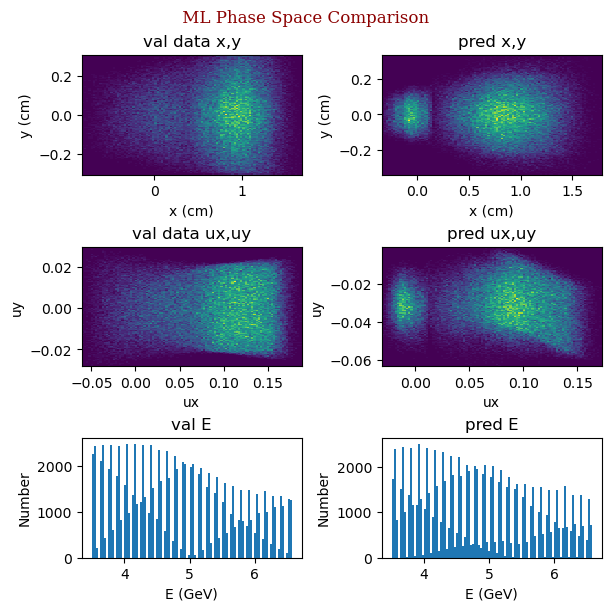

In [37]:
print(len(phase_space_pred))
print("pred data")
print(phase_space_pred)
print("val data")
unpack_output_val = output_LhARA_val.reshape((-1, 6))
print(unpack_output_val)

part_per_index = 18750
#unpack_output_val = output_val*output_norm_array
#part_num = len(part_lost_pred)
#pred_survive_index = []
val_survive_index = []
same_survive_thresh = 0.5
output_lost_val_re = output_lost_val.reshape(-1)
for i in range(0,part_num):
    #if (phase_space_pred[i][3]+phase_space_pred[i][4]+phase_space_pred[i][5])<1e-1:
        #pred_survive_index.append(i)
    if output_lost_val_re[i]>same_survive_thresh:
        val_survive_index.append(i)
    
#val_survive_index = np.asarray(val_survive_index, dtype=np.intp)
unpack_output_val = unpack_output_val[val_survive_index_slice]#val_survive_index_slice
phase_space_pred_survive = phase_space_pred[val_survive_index_slice]

#print("val surving particle num : "+str(len(val_survive_index))+", pred surving particle num : "+str(len(pred_survive_index))+", diff : "+str(100*(len(val_survive_index)-len(pred_survive_index))/len(val_survive_index))+" %")
print("val surving particle num : "+str(len(val_survive_index)))
      
fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(6., 6.), \
                                layout="constrained")
# add an artist, in this case a nice label in the middle...
Ttl = " ML Phase Space Comparison "

fig.suptitle(Ttl, fontdict=font)

axs[0, 0].set_title('val data x,y')
axs[0, 0].hist2d(unpack_output_val[:,0], unpack_output_val[:,2], bins=100)
axs[0, 0].set_xlabel('x (cm)')
axs[0, 0].set_ylabel('y (cm)')

axs[0, 1].set_title('pred x,y')
axs[0, 1].hist2d(phase_space_pred_survive[:,0], phase_space_pred_survive[:,2], bins=100)
axs[0, 1].set_xlabel('x (cm)')
axs[0, 1].set_ylabel('y (cm)')

axs[1, 0].set_title('val data ux,uy')
axs[1, 0].hist2d(unpack_output_val[:,1], unpack_output_val[:,3], bins=100)
axs[1, 0].set_xlabel('ux')
axs[1, 0].set_ylabel('uy')

axs[1, 1].set_title('pred ux,uy')
axs[1, 1].hist2d(phase_space_pred_survive[:,1], phase_space_pred_survive[:,3], bins=100)
axs[1, 1].set_xlabel('ux')
axs[1, 1].set_ylabel('uy')

axs[2, 0].set_title('val E')
axs[2, 0].hist(unpack_output_val[:,5], 100)
axs[2, 0].set_yscale('linear')
axs[2, 0].set_xlabel('E (GeV)')
axs[2, 0].set_ylabel('Number')

axs[2, 1].set_title('pred E')
axs[2, 1].hist(phase_space_pred_survive[:,5], 100)
axs[2, 1].set_yscale('linear')
axs[2, 1].set_xlabel('E (GeV)')
axs[2, 1].set_ylabel('Number')

plt.show()

In [38]:
#=================================================================================
#Advanced architechture with LhARA style with delta value as data instead of raw values and invariant E
#=================================================================================

In [39]:
base_matrix = tf.eye(6)

#just get the residual
class TransferMatrixModel_res_val_E_invar(tf.keras.Model):

    def __init__(self):
        super().__init__()

        self.network = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(17,)),

            tf.keras.layers.Dense(128, activation="tanh"),
            tf.keras.layers.Dense(128, activation="tanh"),
            tf.keras.layers.Dense(128, activation="tanh"),

            tf.keras.layers.Dense(30)
        ])

    def call(self, field):

        REDUCED_DIM = 5
        # field:
        # (N_fields, 17)

        matrix_elements = self.network(field)

        A = tf.cast(tf.reshape(matrix_elements,(-1, 5, 6)), dtype=tf.float32)

        # Add a fixed last column: [0, 0, 0, 0, 0, 1]^T
        #top = tf.keras.layers.Lambda(lambda a: tf.concat([a, tf.zeros((tf.shape(a)[0], REDUCED_DIM, 1))], axis=2))(A)
        
        # Add a fixed last row: [0, 0, 0, 0, 0, 1]
        bottom = tf.keras.layers.Lambda(lambda a: tf.tile(tf.constant([[[0., 0., 0., 0., 0., 0.]]]), [tf.shape(a)[0], 1, 1]))(A)
        
        M = tf.keras.layers.Concatenate(axis=1, name="transfer_matrix")([A, bottom])

        return M

In [40]:
optimizer = tf.keras.optimizers.Adam(learning_rate=1e-3)
LhARA_res_val_E_invar_model = TransferMatrixModel_res_val_E_invar()

dummy_field = tf.zeros((1, 17))
_ = LhARA_res_val_E_invar_model(dummy_field)

LhARA_res_val_E_invar_model.summary()

@tf.function
def LhARA_res_val_E_invar_train_step(field, phase_space_before, phase_space_after, particle_weights):

    with tf.GradientTape() as tape:

        M = LhARA_res_val_E_invar_model(field)
        phase_space_after_residual = phase_space_after - tf.einsum("ij,bpj->bpi", base_matrix, phase_space_before)#calc residual of phase space
        phase_space_residual_pred = tf.einsum("bij,bpj->bpi", M, phase_space_before)

        particle_loss = tf.reduce_mean(tf.square(phase_space_residual_pred - phase_space_after_residual), axis=-1)
        weighted_loss = particle_loss * particle_weights

        loss_per_setting = (tf.reduce_sum(weighted_loss, axis=1)/tf.maximum(tf.reduce_sum(particle_weights, axis=1),1.0))
        loss = tf.reduce_sum(loss_per_setting)

    gradients = tape.gradient(loss, LhARA_res_val_E_invar_model.trainable_variables)
    optimizer.apply_gradients(zip(gradients,LhARA_res_val_E_invar_model.trainable_variables))

    return loss

@tf.function
def LhARA_res_val_E_invar_validation_step(field, phase_space_before, phase_space_after):

    # One transfer matrix per field configuration
    M = LhARA_res_val_E_invar_model(field, training=False)

    # Calculate residual phase space
    phase_space_after_residual = (phase_space_after - tf.einsum("ij,bpj->bpi", base_matrix, phase_space_before))

    # Predict residual phase space
    phase_space_residual_pred = tf.einsum("bij,bpj->bpi", M, phase_space_before)

    # Calculate validation loss
    loss = tf.reduce_mean(tf.square( phase_space_residual_pred - phase_space_after_residual))

    return loss

Model: "transfer_matrix_model_res_val_e_invar"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 sequential_4 (Sequential)   (None, 30)                39198     
                                                                 
Total params: 39,198
Trainable params: 39,198
Non-trainable params: 0
_________________________________________________________________


In [41]:
history = {"loss": [], "val_loss": []}
#train the model
num_epochs = 48000
#Not worried about memory or local minima
batchSize = len(input_phase_space_train[0])

starttime = time.time()
for epoch in range(num_epochs):
    epoch_losses = []
    val_losses = []

    loss = LhARA_res_val_E_invar_train_step(input_para_train, input_LhARA_train, output_LhARA_train, output_lost_train)
    val_loss = LhARA_res_val_E_invar_validation_step(input_para_val, input_LhARA_val, output_LhARA_val)
    
    epoch_losses.append(float(loss.numpy()))
    epoch_loss = sum(epoch_losses) / len(epoch_losses)
    
    val_losses.append(float(val_loss.numpy()))
    epoch_val_loss = sum(val_losses) / len(val_losses)
    
    history["loss"].append(epoch_loss)
    history["val_loss"].append(epoch_val_loss)

    if epoch % 1000 == 0:
        print(f"Epoch {epoch}: loss = {loss.numpy()}, "
            f"val_loss: {epoch_val_loss:.6e}")

timepass = time.time()-starttime
print("training completed in "+str(timepass)+" sec. for "+str(num_epochs)+" epochs "+str(timepass/num_epochs)+"  sec. per epoch")

full_model_filename = 'FFA_LhARA_E_invar_trans_matrix_ML'
saved_model_directory = 'ML_FFA_sample'

model_filename = os.path.join(saved_model_directory, full_model_filename)
model.save(model_filename)

Epoch 0: loss = 89.51045227050781, val_loss: 5.134969e-01
Epoch 1000: loss = 0.2801465392112732, val_loss: 3.633140e-02
Epoch 2000: loss = 0.1318269968032837, val_loss: 1.976283e-02
Epoch 3000: loss = 0.11357226967811584, val_loss: 2.280351e-02
Epoch 4000: loss = 0.11458267271518707, val_loss: 1.768628e-02
Epoch 5000: loss = 0.12376562505960464, val_loss: 1.853523e-02
Epoch 6000: loss = 0.09609359502792358, val_loss: 2.726557e-02
Epoch 7000: loss = 0.19070512056350708, val_loss: 2.275960e-02
Epoch 8000: loss = 0.0813959538936615, val_loss: 2.079326e-02
Epoch 9000: loss = 0.10852347314357758, val_loss: 2.447644e-02
Epoch 10000: loss = 0.08468496799468994, val_loss: 2.307278e-02
Epoch 11000: loss = 0.07898598909378052, val_loss: 1.991650e-02
Epoch 12000: loss = 0.0799429789185524, val_loss: 1.942205e-02
Epoch 13000: loss = 0.07824355363845825, val_loss: 2.007907e-02
Epoch 14000: loss = 0.08914013206958771, val_loss: 1.971206e-02
Epoch 15000: loss = 0.08953403681516647, val_loss: 1.987401

In [42]:
trans_M_pred = LhARA_res_val_E_invar_model.predict(input_para_val) + base_matrix.numpy()

print("Predicted transfer matrix:")
print(np.array2string(trans_M_pred[0], precision=6, suppress_small=True))#
start_index = 0
end_index = 15
phase_space_pred = tf.einsum("bij,bpj->bpi", trans_M_pred, input_LhARA_val)#[start_index:end_index]

phase_space_pred = tf.reshape(phase_space_pred, (-1, 6))
phase_space_pred = phase_space_pred.numpy()

ML_result_df = pd.DataFrame(phase_space_pred, columns=fixfield_phase_space_headers)
#fixfield_headers =  ["m0 [MeV*c^-2]", "q [unit charge]", "x [m]", "y [m]", "z [m]", "Ptot [MeV/c]", "ux []", "uy []", "uz []"]
#ML_result_df["m0 [MeV*c^-2]"] = input_df["m0 [MeV*c^-2]"] 
#ML_result_df["q [unit charge]"] = input_df["q [unit charge]"] 
#ML_result_df["Ptot [MeV/c]"] = input_df["Ptot [MeV/c]"] 

out_name = "ML_FFA_sample/FFA_ML_trans_matrix_result.dat"
    
print("writing to file : "+out_name)

writeFile(ML_result_df, out_name)

1/1 [==============================] - 0s 60ms/step
Predicted transfer matrix:
[[ 0.249549  8.220438  0.000042 -0.076479 -3.220963  0.1375  ]
 [-0.074513  0.105662 -0.000488 -0.010398  1.225696  0.017266]
 [ 0.000936  0.074814  0.595986  7.603828  1.105146 -0.001304]
 [-0.00011   0.004074 -0.020123  0.759595  0.055238  0.000037]
 [ 0.005566  0.00635  -0.003159  0.005719  0.891901 -0.005659]
 [ 0.        0.        0.        0.        0.        1.      ]]
writing to file : ML_FFA_sample/FFA_ML_trans_matrix_result.dat


140625
pred data
[[ 4.1614717e-01  4.9558073e-02  2.9723654e-02  1.8250188e-02
  -1.8596752e-02  3.5255163e+00]
 [ 4.7453746e-01  6.9158003e-02 -1.6687553e-01 -4.3653701e-03
  -2.0197982e-02  3.5416017e+00]
 [ 4.5318130e-01  7.2809748e-02  1.4202996e-01  1.1010709e-02
  -2.1078590e-02  3.5632341e+00]
 ...
 [ 1.2442440e+00  1.5655288e-01 -1.3685782e-01 -1.3929851e-02
  -3.5793673e-02  6.5043912e+00]
 [ 1.2014102e+00  1.4305405e-01  3.8692698e-02  2.0964176e-03
  -3.5012554e-02  6.5135579e+00]
 [ 1.0691624e+00  1.4861614e-01 -1.1074053e-02 -6.2382296e-03
  -3.5802890e-02  6.5103960e+00]]
val data
[[ 1.9826829e-01  1.9062180e-02  4.1343279e-02  2.2360049e-02
   0.0000000e+00  3.5255165e+00]
 [ 2.9965061e-01  4.1944850e-02 -2.1133350e-01 -3.0730129e-03
   0.0000000e+00  3.5416019e+00]
 [ 2.8977621e-01  4.8330210e-02  1.9566250e-01  1.2318580e-02
   0.0000000e+00  3.5632346e+00]
 ...
 [ 1.1991251e+00  1.5194960e-01 -1.7920840e-01 -1.7192330e-02
   0.0000000e+00  6.5043917e+00]
 [ 1.1606530e

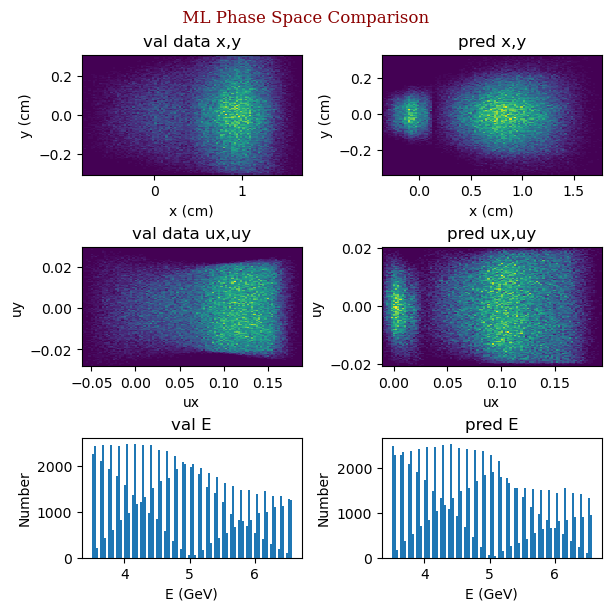

In [43]:
print(len(phase_space_pred))
print("pred data")
print(phase_space_pred)
print("val data")
unpack_output_val = output_LhARA_val.reshape((-1, 6))
print(unpack_output_val)

part_per_index = 18750
#unpack_output_val = output_val*output_norm_array
#part_num = len(part_lost_pred)
#pred_survive_index = []
val_survive_index = []
same_survive_thresh = 0.5
output_lost_val_re = output_lost_val.reshape(-1)
for i in range(0,part_num):
    #if (phase_space_pred[i][3]+phase_space_pred[i][4]+phase_space_pred[i][5])<1e-1:
        #pred_survive_index.append(i)
    if output_lost_val_re[i]>same_survive_thresh:
        val_survive_index.append(i)
    
#val_survive_index = np.asarray(val_survive_index, dtype=np.intp)
unpack_output_val = unpack_output_val[val_survive_index_slice]#val_survive_index_slice
phase_space_pred_survive = phase_space_pred[val_survive_index_slice]

#print("val surving particle num : "+str(len(val_survive_index))+", pred surving particle num : "+str(len(pred_survive_index))+", diff : "+str(100*(len(val_survive_index)-len(pred_survive_index))/len(val_survive_index))+" %")
print("val surving particle num : "+str(len(val_survive_index)))
      
fig, axs = plt.subplots(nrows=3, ncols=2, figsize=(6., 6.), \
                                layout="constrained")
# add an artist, in this case a nice label in the middle...
Ttl = " ML Phase Space Comparison "

fig.suptitle(Ttl, fontdict=font)

axs[0, 0].set_title('val data x,y')
axs[0, 0].hist2d(unpack_output_val[:,0], unpack_output_val[:,2], bins=100)
axs[0, 0].set_xlabel('x (cm)')
axs[0, 0].set_ylabel('y (cm)')

axs[0, 1].set_title('pred x,y')
axs[0, 1].hist2d(phase_space_pred_survive[:,0], phase_space_pred_survive[:,2], bins=100)
axs[0, 1].set_xlabel('x (cm)')
axs[0, 1].set_ylabel('y (cm)')

axs[1, 0].set_title('val data ux,uy')
axs[1, 0].hist2d(unpack_output_val[:,1], unpack_output_val[:,3], bins=100)
axs[1, 0].set_xlabel('ux')
axs[1, 0].set_ylabel('uy')

axs[1, 1].set_title('pred ux,uy')
axs[1, 1].hist2d(phase_space_pred_survive[:,1], phase_space_pred_survive[:,3], bins=100)
axs[1, 1].set_xlabel('ux')
axs[1, 1].set_ylabel('uy')

axs[2, 0].set_title('val E')
axs[2, 0].hist(unpack_output_val[:,5], 100)
axs[2, 0].set_yscale('linear')
axs[2, 0].set_xlabel('E (GeV)')
axs[2, 0].set_ylabel('Number')

axs[2, 1].set_title('pred E')
axs[2, 1].hist(phase_space_pred_survive[:,5], 100)
axs[2, 1].set_yscale('linear')
axs[2, 1].set_xlabel('E (GeV)')
axs[2, 1].set_ylabel('Number')

plt.show()